In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!git clone https://github.com/elifsudayi/food-recipe-finder.git
%cd food-recipe-finder
!pip install -q -r requirements.txt

!tar -xf /content/drive/MyDrive/swe015/food10.tar -C /content
!mkdir -p models results

Mounted at /content/drive
Cloning into 'food-recipe-finder'...
remote: Enumerating objects: 38, done.
remote: Counting objects: 100% (38/38), done.
remote: Compressing objects: 100% (25/25), done.
remote: Total 38 (delta 13), reused 34 (delta 9), pack-reused 0 (from 0)
Receiving objects: 100% (38/38), 58.68 KiB | 4.19 MiB/s, done.
Resolving deltas: 100% (13/13), done.
/content/food-recipe-finder
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import sys, json; sys.path.append(".")
import torch
from src.config import SEED
from src.utils import set_seed, get_device, hardware_info, count_params, model_size_mb, latency_ms
from src.image.data import get_loaders
from src.image.models import build_vgg16, set_trainable, head_and_backbone_params, BLOCK5_START
from src.image.train import fit, evaluate

set_seed(SEED)
device = get_device()
print(device, hardware_info()["gpu"])

IMG = 224
loaders, class_names = get_loaders("/content/food10", img_size=IMG, batch_size=64)
print(class_names)

model = build_vgg16(num_classes=len(class_names), dropout=0.5)
set_trainable(model, unfreeze_from=None)          # A: head only
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("total parameter:", count_params(model), "| trained:", n_train)

cuda Tesla T4
['caesar_salad', 'chicken_curry', 'french_fries', 'hamburger', 'ice_cream', 'omelette', 'pancakes', 'pizza', 'spaghetti_carbonara', 'sushi']
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:06<00:00, 87.7MB/s]


total parameter: 27565386 | trained: 12850698


In [ ]:
hist_fe, best_fe = fit(model, loaders, device, epochs=10, lr=0.01,
                       weight_decay=5e-4, ckpt_path="models/vgg16_fe.pt", label="[FE] ")
print("best val top-1 (FE):", best_fe)

[FE] ep 01/10 | train loss 1.085 acc 0.662 | val loss 0.597 top1 0.813 top5 0.976 | 50s
[FE] ep 02/10 | train loss 0.877 acc 0.728 | val loss 0.659 top1 0.801 top5 0.971 | 50s
[FE] ep 03/10 | train loss 0.821 acc 0.747 | val loss 0.609 top1 0.807 top5 0.980 | 48s
[FE] ep 04/10 | train loss 0.724 acc 0.778 | val loss 0.549 top1 0.829 top5 0.974 | 49s
[FE] ep 05/10 | train loss 0.651 acc 0.799 | val loss 0.538 top1 0.840 top5 0.978 | 50s
[FE] ep 06/10 | train loss 0.597 acc 0.814 | val loss 0.512 top1 0.844 top5 0.979 | 50s
[FE] ep 07/10 | train loss 0.527 acc 0.839 | val loss 0.521 top1 0.849 top5 0.981 | 49s
[FE] ep 08/10 | train loss 0.481 acc 0.848 | val loss 0.502 top1 0.853 top5 0.983 | 49s
[FE] ep 09/10 | train loss 0.462 acc 0.861 | val loss 0.496 top1 0.854 top5 0.981 | 51s
[FE] ep 10/10 | train loss 0.433 acc 0.862 | val loss 0.492 top1 0.857 top5 0.984 | 50s
best val top-1 (FE): 0.857


In [ ]:
model.load_state_dict(torch.load("models/vgg16_fe.pt", map_location=device))
set_trainable(model, unfreeze_from=BLOCK5_START)   # block5 + head
head, backbone = head_and_backbone_params(model)
print("trained parameter:", sum(p.numel() for p in model.parameters() if p.requires_grad))

hist_ft, best_ft = fit(model, loaders, device, epochs=15, weight_decay=5e-4,
                       param_groups=[{"params": head, "lr": 1e-3},
                                     {"params": backbone, "lr": 5e-4}],
                       ckpt_path="models/vgg16_ft.pt", label="[FT] ")
print("best val top-1 (FT):", best_ft)

trained parameter: 19930122
[FT] ep 01/15 | train loss 0.441 acc 0.862 | val loss 0.473 top1 0.854 top5 0.985 | 50s
[FT] ep 02/15 | train loss 0.395 acc 0.878 | val loss 0.470 top1 0.863 top5 0.984 | 52s
[FT] ep 03/15 | train loss 0.361 acc 0.882 | val loss 0.473 top1 0.863 top5 0.988 | 50s
[FT] ep 04/15 | train loss 0.346 acc 0.889 | val loss 0.449 top1 0.874 top5 0.986 | 51s
[FT] ep 05/15 | train loss 0.336 acc 0.895 | val loss 0.439 top1 0.878 top5 0.987 | 51s
[FT] ep 06/15 | train loss 0.308 acc 0.903 | val loss 0.448 top1 0.876 top5 0.988 | 50s
[FT] ep 07/15 | train loss 0.290 acc 0.910 | val loss 0.442 top1 0.871 top5 0.983 | 52s
[FT] ep 08/15 | train loss 0.277 acc 0.908 | val loss 0.436 top1 0.877 top5 0.984 | 50s
[FT] ep 09/15 | train loss 0.276 acc 0.913 | val loss 0.433 top1 0.880 top5 0.986 | 51s
[FT] ep 10/15 | train loss 0.267 acc 0.912 | val loss 0.433 top1 0.874 top5 0.987 | 51s
[FT] ep 11/15 | train loss 0.269 acc 0.911 | val loss 0.432 top1 0.879 top5 0.989 | 50s
[FT]

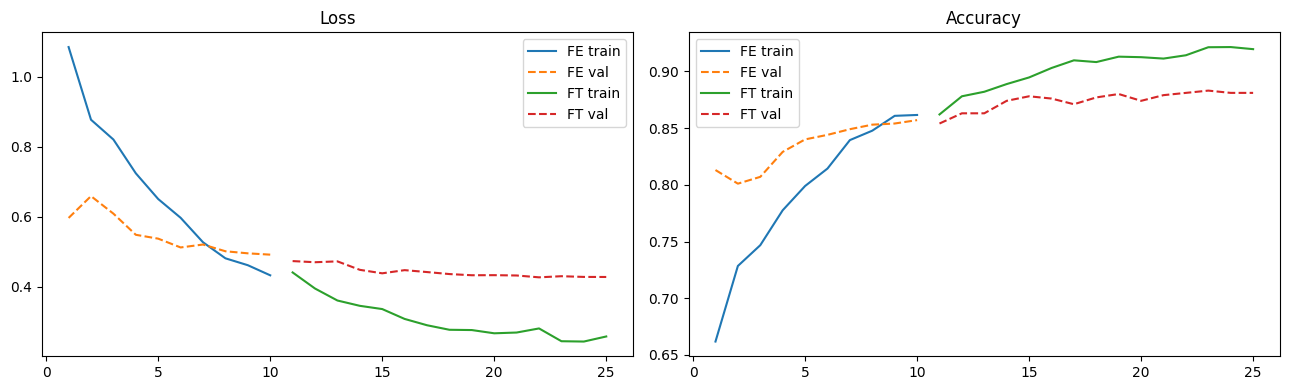

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, h, off in [("FE", hist_fe, 0), ("FT", hist_ft, len(hist_fe))]:
    ep = [x["epoch"] + off for x in h]
    ax[0].plot(ep, [x["train_loss"] for x in h], label=f"{name} train")
    ax[0].plot(ep, [x["val_loss"] for x in h], "--", label=f"{name} val")
    ax[1].plot(ep, [x["train_acc"] for x in h], label=f"{name} train")
    ax[1].plot(ep, [x["val_top1"] for x in h], "--", label=f"{name} val")
ax[0].set_title("Loss"); ax[1].set_title("Accuracy")
ax[0].legend(); ax[1].legend()
plt.tight_layout(); plt.savefig("results/vgg16_curves.png", dpi=150); plt.show()

In [ ]:
test_loader = get_loaders("/content/food10", IMG, splits=("test",))[0]["test"]
out = {}
for tag, ckpt in [("vgg16_feature_extraction_fp32", "models/vgg16_fe.pt"),
                  ("vgg16_finetuned_fp32", "models/vgg16_ft.pt")]:
    m = build_vgg16(num_classes=len(class_names), pretrained=False)
    m.load_state_dict(torch.load(ckpt, map_location="cpu"))
    r = evaluate(m.to(device), test_loader, device)
    out[tag] = {"test_top1": r["top1"], "test_top5": r["top5"],
                "size_mb": model_size_mb(m), "params": count_params(m)}
    print(tag, out[tag])

# The architecture is the same in both; we measure the latency once on the CPU
m_cpu = build_vgg16(num_classes=len(class_names), pretrained=False)
m_cpu.load_state_dict(torch.load("models/vgg16_ft.pt", map_location="cpu"))
lat = latency_ms(m_cpu, input_shape=(1, 3, IMG, IMG), runs=100, device="cpu")
for k in out: out[k]["latency_cpu_ms"] = lat
out["class_names"], out["hardware"] = class_names, hardware_info()

json.dump(out, open("results/vgg16_metrics.json", "w"), indent=2)
print(json.dumps(out, indent=2))

vgg16_feature_extraction_fp32 {'test_top1': 0.8984, 'test_top5': 0.9944, 'size_mb': 110.272201, 'params': 27565386}
vgg16_finetuned_fp32 {'test_top1': 0.9208, 'test_top5': 0.9956, 'size_mb': 110.272201, 'params': 27565386}
{
  "vgg16_feature_extraction_fp32": {
    "test_top1": 0.8984,
    "test_top5": 0.9944,
    "size_mb": 110.272201,
    "params": 27565386,
    "latency_cpu_ms": {
      "mean_ms": 386.5601789699985,
      "std_ms": 72.51335943084001,
      "runs": 100
    }
  },
  "vgg16_finetuned_fp32": {
    "test_top1": 0.9208,
    "test_top5": 0.9956,
    "size_mb": 110.272201,
    "params": 27565386,
    "latency_cpu_ms": {
      "mean_ms": 386.5601789699985,
      "std_ms": 72.51335943084001,
      "runs": 100
    }
  },
  "class_names": [
    "caesar_salad",
    "chicken_curry",
    "french_fries",
    "hamburger",
    "ice_cream",
    "omelette",
    "pancakes",
    "pizza",
    "spaghetti_carbonara",
    "sushi"
  ],
  "hardware": {
    "cpu": "Intel(R) Xeon(R) CPU @ 2.00GH

In [ ]:
!cp models/vgg16_fe.pt models/vgg16_ft.pt /content/drive/MyDrive/swe015/
!cp results/vgg16_metrics.json results/vgg16_curves.png /content/drive/MyDrive/swe015/